<a href="https://colab.research.google.com/github/AYMEEEN444/ir-tfidf-ocr-tesseract/blob/main/TF_IDF%2CORC_Tesseract.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
!pip in

ERROR: unknown command "in"


In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
# ---------------------------
# استيراد المكتبات
# ---------------------------
import re              # لاستخراج الكلمات باستعمال regex
import os              # للتعامل مع الملفات والمجلدات
import json            # لحفظ الـ index في ملف JSON
import unicodedata     # لحذف الـ accents (é → e)
from collections import Counter, defaultdict  # Counter لحساب التكرار


# ---------------------------
# دالة حذف الـ accents
# مثال: école تصبح ecole
# ---------------------------
def remove_accents(text):
    return ''.join(
        c for c in unicodedata.normalize('NFD', text)
        if unicodedata.category(c) != 'Mn'
    )


# ---------------------------
# كلمات فارغة بالفرنسية (لا تفيد في البحث)
# ---------------------------
stop_words = {
    "le","la","les","un","une","des","de","du","et","ou","a","à",
    "en","dans","par","pour","avec","sur","ce","cet","cette",
    "il","elle","ils","elles","nous","vous","je","tu",
    "est","sont","etre","avoir","ete","comme","plus","moins",
    "au","aux","se","sa","son","ses","ne","pas"
}


# ---------------------------
# دالة تبسيط الكلمات (Lemmatization بسيطة)
# ---------------------------
def lemmatize(word):

    # إذا الكلمة جمع نحذف s
    if word.endswith("s") and len(word) > 4:
        return word[:-1]

    # حذف es في بعض الحالات
    if word.endswith("es") and len(word) > 4:
        return word[:-2]

    # تبسيط بعض صيغ الأفعال
    if word.endswith("aient"):
        return word[:-5]
    if word.endswith("ait"):
        return word[:-3]
    if word.endswith("ant"):
        return word[:-3]
    if word.endswith("er"):
        return word[:-2]

    return word


# ---------------------------
# دالة فهرسة ملف واحد
# تأخذ مسار الملف وترجع عدد تكرار كل كلمة
# ---------------------------
def index_document(path):
    # تقرا ملف و ترجع عدد تكرار الكلمات

    try:
        # نحاول نفتح الملف بـ utf-8
        with open(path, "r", encoding="utf-8") as f:
            texte = f.read().lower()  # نقرا النص و نصغّرو

    except UnicodeDecodeError:
        # إذا ما يخدمش utf-8 نجرب latin-1
        with open(path, "r", encoding="latin-1") as f:
            texte = f.read().lower()

    texte = remove_accents(texte)  # نحيو é è ...

    mots = re.findall(r"\b[a-z]+\b", texte)  # نخرج الكلمات برك

    mots = [m for m in mots if m not in stop_words]  # نحيو الكلمات الفارغة

    mots = [lemmatize(m) for m in mots]  # نرجعو الكلمة لأصلها

    return Counter(mots)  # نحسبو التكرار


# ---------------------------
# بناء الفهرس العام (Inverted Index)
# ---------------------------

# مسار مجلد النصوص
corpus_path = "/content/drive/MyDrive/projet"

# إنشاء فهرس عام
# الشكل: كلمة → ملف → عدد التكرار
index_global = defaultdict(dict)

# المرور على كل ملف في المجلد
for fichier in os.listdir(corpus_path):

    # نتأكد أنه ملف نصي
    if fichier.endswith(".txt"):

        path = os.path.join(corpus_path, fichier)

        # فهرسة الملف
        freq_doc = index_document(path)

        # إضافة النتائج للفهرس العام
        for mot, freq in freq_doc.items():
            index_global[mot][fichier] = freq


# ---------------------------
# حفظ الفهرس في ملف JSON
# ---------------------------
with open("/content/drive/MyDrive/index.json", "w", encoding="utf-8") as f:
    json.dump(dict(index_global), f, indent=4)

print(" تم إنشاء الفهرس بنجاح!")

 تم إنشاء الفهرس بنجاح!


In [11]:
# ---------------------------
# استيراد math لحساب log و sqrt
# ---------------------------
import math


# ---------------------------
# حساب TF-IDF انطلاقا من index_global
# ---------------------------
def compute_tfidf(index_global):

    # عدد الوثائق
    documents = set()
    for term in index_global:
        documents.update(index_global[term].keys())

    N = len(documents)  # عدد الوثائق الكل

    tfidf = {}

    for term, docs in index_global.items():

        df = len(docs)  # عدد الوثائق اللي فيها الكلمة
        idf = math.log(N / df)

        for doc, tf in docs.items():

            if doc not in tfidf:
                tfidf[doc] = {}

            tfidf[doc][term] = tf * idf  # TF-IDF

    return tfidf

# TF  = document عدد تكرار الكلمة في
#IDF = corpus قداش الكلمة نادرة في


# ---------------------------
# حساب Cosinus Similarité
# ---------------------------
def cosine_similarity(vec1, vec2):

    # الكلمات المشتركة
    intersection = set(vec1.keys()) & set(vec2.keys())

    # produit scalaire
    numerator = sum(vec1[x] * vec2[x] for x in intersection)

    sum1 = sum(v**2 for v in vec1.values())
    sum2 = sum(v**2 for v in vec2.values())

    denominator = math.sqrt(sum1) * math.sqrt(sum2)

    if denominator == 0:
        return 0

    return numerator / denominator


# ---------------------------
# MODELE VECTORIEL
# ---------------------------
def vector_model(query, index_global):
  #TF (Term Frequency)
  #IDF (Inverse Document Frequency)
    # نحسب TF-IDF
    tfidf = compute_tfidf(index_global)

    # نحضر query بنفس المعالجة متاع الوثائق
    query = remove_accents(query.lower())
    mots = re.findall(r"\b[a-z]+\b", query)
    mots = [m for m in mots if m not in stop_words]
    mots = [lemmatize(m) for m in mots]

    query_vec = Counter(mots)  # TF متاع query

    scores = {}

    for doc in tfidf:
        score = cosine_similarity(query_vec, tfidf[doc])
        scores[doc] = score

    # ترتيب تنازلي حسب score
    return sorted(scores.items(), key=lambda x: x[1], reverse=True)


# ---------------------------
# MODELE BOOLEEN
# ---------------------------
def boolean_model(query, index_global):

    query = query.lower()

    # استخراج الوثائق الكل
    documents = set()
    for term in index_global:
        documents.update(index_global[term].keys())

    results = documents.copy()

    if " and " in query:

        terms = query.split(" and ")

        for term in terms:
            term = remove_accents(term.strip())
            docs = set(index_global.get(term, {}).keys())
            results = results & docs  # intersection

    elif " or " in query:

        results = set()
        terms = query.split(" or ")

        for term in terms:
            term = remove_accents(term.strip())
            docs = set(index_global.get(term, {}).keys())
            results = results | docs  # union

    elif " not " in query:

        term = query.split(" not ")[1]
        term = remove_accents(term.strip())
        docs = set(index_global.get(term, {}).keys())
        results = documents - docs  # difference

    else:
        term = remove_accents(query.strip())
        results = set(index_global.get(term, {}).keys())

    return list(results)


# ---------------------------
# TEST
# ---------------------------
print("\n----- MODELE VECTORIEL -----")
print("\n==============================")
print("RESULTATS - MODELE VECTORIEL")
print("==============================")

results = vector_model("intelligence artificielle", index_global)

for i, (doc, score) in enumerate(results, 1):
    if score > 0:   # نعرضو كان الوثائق اللي عندها علاقة
        print(f"{i}. 📄 {doc}  -->  Score = {score:.4f}")

print("\n----- MODELE BOOLEEN -----")
print("\n==============================")
print("RESULTATS - MODELE BOOLEEN")
print("==============================")

results_bool = boolean_model("intelligence AND artificielle", index_global)

if results_bool:
    for i, doc in enumerate(results_bool, 1):
        print(f"{i}. {doc}")
else:
    print("Aucun document trouvé")


----- MODELE VECTORIEL -----

RESULTATS - MODELE VECTORIEL
1. 📄 Nouveau document texte (6) - Copie.txt  -->  Score = 0.1143

----- MODELE BOOLEEN -----

RESULTATS - MODELE BOOLEEN
Aucun document trouvé


In [5]:
# =========================================================
# 🔵 PARTIE 4 : MOTEUR DE RECHERCHE
# =========================================================

# ---------------------------
# قراءة requête من المستخدم
# ---------------------------
query = input("اكتب البحث متاعك: ")


# ---------------------------
# معالجة الـ query (نفس traitement متاع الوثائق)
# ---------------------------
query_clean = remove_accents(query.lower())

mots = re.findall(r"\b[a-z]+\b", query_clean)

mots = [m for m in mots if m not in stop_words]

mots = [lemmatize(m) for m in mots]


# ---------------------------
# نرجعو query جديدة نظيفة
# ---------------------------
query_final = " ".join(mots)


# ---------------------------
# البحث بالمودال الفيكتوري
# ---------------------------
print("\n==============================")
print("RESULTATS - MODELE VECTORIEL")
print("==============================")

results_vector = vector_model(query_final, index_global)

for i, (doc, score) in enumerate(results_vector, 1):
    if score > 0:
        print(f"{i}. {doc}  --> Score = {score:.4f}")


# ---------------------------
# البحث بالمودال البولياني
# ---------------------------
print("\n==============================")
print("RESULTATS - MODELE BOOLEEN")
print("==============================")

results_bool = boolean_model(query_final, index_global)

if results_bool:
    for i, doc in enumerate(results_bool, 1):
        print(f"{i}. {doc}")
else:
    print("Aucun document trouvé")

🔎 اكتب البحث متاعك: intelegence artificiel

🔎 RESULTATS - MODELE VECTORIEL

🔎 RESULTATS - MODELE BOOLEEN
❌ Aucun document trouvé



📄 Documents trouvés:
['Nouveau document texte (6) - Copie.txt']

📌 Relevant docs (test):
['Nouveau document texte (6) - Copie.txt', 'doc2.txt']

📊 EVALUATION
Precision = 1.00
Recall    = 0.50


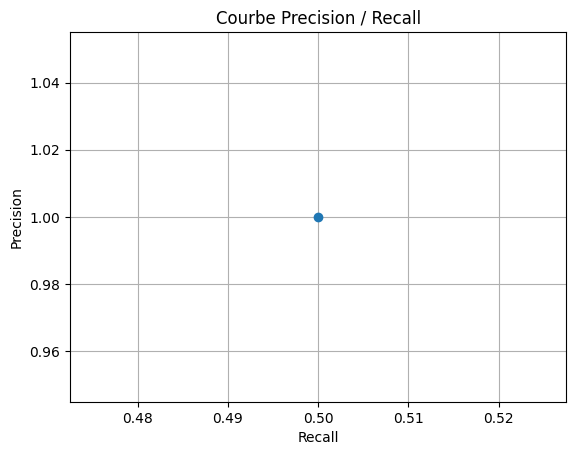

In [6]:
# =========================================================
# 🔵 PARTIE 5 : EVALUATION DU MOTEUR
# =========================================================

import matplotlib.pyplot as plt


# ---------------------------
# حساب Precision و Recall
# ---------------------------
def precision_recall(results, relevant_docs):
    """
    results: الوثائق اللي رجعهم النظام
    relevant_docs: الوثائق الصحيحة (ground truth)
    """

    # نحولوهم لـ set باش ننجمو نعملو intersection
    results_set = set(results)
    relevant_set = set(relevant_docs)

    # الوثائق الصحيحة اللي النظام لقاهم (True Positive)
    true_positive = results_set & relevant_set

    # ---------------------------
    # Precision قداش النتائج صحيحة
    # ---------------------------
    # = عدد الوثائق الصحيحة / عدد الوثائق اللي رجعهم النظام
    # مثال:
    # results = [D1, D2, D3]
    # relevant = [D1, D3]
    # → true_positive = [D1, D3]
    # → precision = 2 / 3
    precision = len(true_positive) / len(results_set) if results_set else 0

    # ---------------------------
    # Recall قداش لقيت من الكل الصحيح
    # ---------------------------
    # = عدد الوثائق الصحيحة / عدد الوثائق الصحيحة الكل
    # مثال:
    # relevant = [D1, D3, D4]
    # true_positive = [D1, D3]
    # → recall = 2 / 3
    recall = len(true_positive) / len(relevant_set) if relevant_set else 0

    return precision, recall


# =========================================================
# TEST
# =========================================================

query = "intelligence artificielle"

# نطبق المودال الفيكتوري
results_vector = vector_model(query, index_global)

# ناخذو غير الوثائق اللي عندها score > 0
# يعني الوثائق اللي عندها علاقة بالـ query
docs_vector = [doc for doc, score in results_vector if score > 0]

print("\nDocuments trouvés:")
print(docs_vector)


# ---------------------------
# IMPORTANT :
# هنا عملنا hack صغير (just test)
# ناخذو أول 2 docs ونعتبروهم relevant
# في الواقع لازم relevant_docs يكونو معروفين من قبل (ground truth)
# ---------------------------
# ---------------------------
# relevant_docs (حطهم بيدك)
# ---------------------------
# مثال: الوثائق اللي تعرفهم صحيحين
relevant_docs = [
    "Nouveau document texte (6) - Copie.txt",
    "doc2.txt"
]

print("\nRelevant docs (test):")
print(relevant_docs)


# ---------------------------
# حساب Precision و Recall
# ---------------------------
p, r = precision_recall(docs_vector, relevant_docs)

print("\n==============================")
print("EVALUATION")
print("==============================")

# Precision: قداش من النتائج اللي عطاهم النظام صحيحين
print(f"Precision = {p:.2f}")

# Recall: قداش من الوثائق الصحيحة الكل لقاهم النظام
print(f"Recall    = {r:.2f}")


# =========================================================
# COURBE PRECISION / RECALL
# =========================================================

precisions = []
recalls = []

# k = عدد الوثائق اللي ناخذوهم (Top-k)
for k in range(1, len(docs_vector) + 1):

    # ناخذو أول k documents فقط
    subset = docs_vector[:k]

    # نحسبو precision و recall لهالمجموعة الصغيرة
    p_k, r_k = precision_recall(subset, relevant_docs)

    # نخزنوهم باش نرسمو
    precisions.append(p_k)
    recalls.append(r_k)


# ---------------------------
# رسم الكوربة
# ---------------------------
# X = Recall
# Y = Precision
plt.plot(recalls, precisions, marker='o')

plt.xlabel("Recall")     # المحور الأفقي
plt.ylabel("Precision")  # المحور العمودي
plt.title("Courbe Precision / Recall")

plt.grid()
plt.show()

In [7]:
# =========================================================
#  INSTALL (كانك في Google Colab)
# =========================================================
!apt-get update                       # تحديث النظام
!apt-get install -y tesseract-ocr     # تنصيب Tesseract (OCR)
!apt-get install -y tesseract-ocr-fra # دعم اللغة الفرنسية
!pip install pytesseract pillow       # مكتبات Python


# =========================================================
#  IMPORTS
# =========================================================
from PIL import Image        # باش نحلّو الصور
import pytesseract           # OCR: تحويل image → texte
import unicodedata           # باش نحيو accents (é → e)
import re                    # regex لاستخراج الكلمات


# ---------------------------
# ربط pytesseract مع Tesseract
# ---------------------------
pytesseract.pytesseract.tesseract_cmd = "/usr/bin/tesseract"


# =========================================================
#  دالة حذف accents
# =========================================================
def remove_accents(text):
    # نحيو الحروف كيف é è à → تولي e a
    return ''.join(
        c for c in unicodedata.normalize('NFD', text)
        if unicodedata.category(c) != 'Mn'
    )


# =========================================================
# تنظيف أخطاء OCR
# =========================================================
def clean_text(text):
    # OCR ساعات يغلط في الحروف
    text = text.replace("ñ", "fi")   # مثال: artiñcielle → artificielle
    text = text.replace("ﬁ", "fi")   # ligature
    return text


# =========================================================
# preprocess (تنظيف كامل للنص)
# =========================================================
def preprocess(text):
    text = text.lower()          # نحولو لحروف صغيرة
    text = clean_text(text)      # نصلحو أخطاء OCR
    text = remove_accents(text)  # نحيو accents

    # نخرج الكلمات فقط (من غير أرقام و رموز)
    words = re.findall(r"\b[a-z]+\b", text)

    return words


# =========================================================
# FUNCTION OCR
# =========================================================
def extract_text_from_image(path):
    """
    تقرا الصورة وترجع النص الموجود فيها
    """

    img = Image.open(path)   # نحل الصورة

    # نحولو الصورة لنص (بالفرنسية)
    text = pytesseract.image_to_string(img, lang="fra")

    return text


# =========================================================
# TEST
# =========================================================

# 🔹 حط هنا path متاع الصورة (من Google Drive)
image_path = "/content/drive/MyDrive/image.png"

# استخراج النص
text = extract_text_from_image(image_path)

# تنظيف النص
words = preprocess(text)

# عرض النتيجة النهائية clean
print(" ".join(words))

Hit:1 http://archive.ubuntu.com/ubuntu noble InRelease
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Get:3 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:4 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:5 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:6 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:8 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:9 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [78.0 kB]
Get:10 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 Packages [1,741 kB]
Get:11 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 Packages [2,172 kB]
Get:12 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:13 http://archive.ubuntu.com/ubuntu noble-updates/restricted amd64 Packages [2,240 